# Regularization: L2 and dropout (NumPy)

A 3-layer ReLU network on the "football" problem: given where the goalkeeper's kick lands (2-D, normalized
coordinates), which team gets the ball? With only 211 training points the unregularized network can memorize them.
The implementation is in `model.py` (unit tests in `test_model.py`).

Protocol: the data come as train.csv and val.csv only, so val.csv is split into a **validation** half (used to choose
hyperparameters) and a **test** half (final report only), stratified with a fixed seed. Both halves have about 100 points,
so one example is about 1 percentage point. Every setting is run with 5 random seeds (mean ± std).

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

In [ ]:
!git clone -b feat/regularization-l2-dropout https://github.com/nyawmolny/deep-learning-fundamentals/

In [2]:
%cd deep-learning-fundamentals/02-regularization-and-optimization/regularization/

/content/deep-learning-fundamentals/02-regularization-and-optimization/regularization


In [3]:
!ls

assets	data.py  model.py  __pycache__	test_model.py


In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from data import load_football, plot_decision_boundary, plot_football
from model import RegularizedNetwork, weight_norm

SEEDS = range(5)
DIMS = [2, 40, 20, 1]
LR, ITERS = 0.3, 15000

In [5]:
LOCAL_DATA = Path("data")
DRIVE_DATA = Path("/content/drive/MyDrive/data/02-regularization-and-optimization/regularization/data/")

DATA_DIR = DRIVE_DATA if DRIVE_DATA.exists() else LOCAL_DATA
print("Using data from:", DATA_DIR.resolve())

DRIVE_ASSETS = Path("/content/drive/MyDrive/data/02-regularization-and-optimization/regularization/assets")
LOCAL_ASSETS = Path("./assets")

ASSETS = DRIVE_ASSETS if Path("/content/drive/MyDrive").exists() else LOCAL_ASSETS
ASSETS.mkdir(parents=True, exist_ok=True)
print("Saving assets to:", ASSETS.resolve())

Using data from: /content/drive/MyDrive/data/02-regularization-and-optimization/regularization/data
Saving assets to: /content/drive/MyDrive/data/02-regularization-and-optimization/regularization/assets


## 1. Data

train / val / test sizes: 210 99 100
share of blue (label 1) in train: 0.5
majority-class baseline, test accuracy: 44.0%


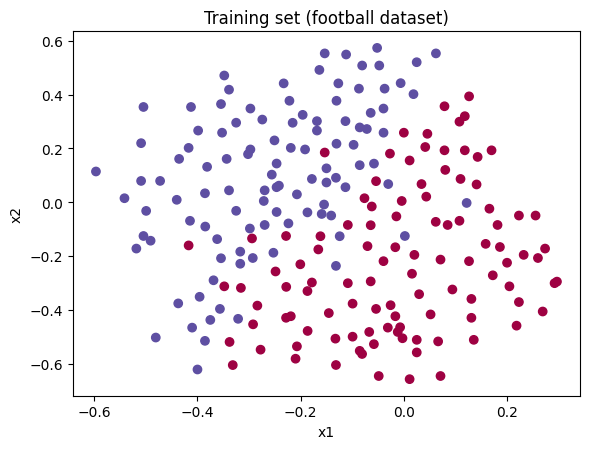

In [6]:
X_tr, Y_tr = load_football(str(DATA_DIR / "train.csv"))       # train.csv: training set
X_hold, Y_hold = load_football(str(DATA_DIR / "val.csv"))     # val.csv: held-out points, split below


def split_val_test(Y, seed=0):# -> tuple[NDArray[Any], NDArray[Any]]:
    # stratified 50/50 split of the held-out points into validation and test indices
    rng = np.random.default_rng(seed)
    val, test = [], []
    for c in (0.0, 1.0):
        idx = rng.permutation(np.where(Y[0] == c)[0])
        half = len(idx) // 2
        val += list(idx[:half])
        test += list(idx[half:])
    return np.array(sorted(val)), np.array(sorted(test))


va_idx, te_idx = split_val_test(Y_hold)
X_va, Y_va = X_hold[:, va_idx], Y_hold[:, va_idx]
X_te, Y_te = X_hold[:, te_idx], Y_hold[:, te_idx]

print("train / val / test sizes:", Y_tr.shape[1], Y_va.shape[1], Y_te.shape[1])
print("share of blue (label 1) in train:", Y_tr.mean().round(3))
majority = float(Y_tr.mean() >= 0.5)
print(f"majority-class baseline, test accuracy: {np.mean(Y_te == majority):.1%}")

fig, ax = plt.subplots(figsize=(6, 4.6))
plot_football(X_tr, Y_tr, ax, plt.cm.Spectral, "Training set (football dataset)")
plt.tight_layout()
plt.savefig(ASSETS / "football_data.png", dpi=150)
plt.show()

## 2. Helpers and the unregularized baseline

In [7]:
def fit_eval(lambd=0.0, keep_prob=1.0):
    rows, models = [], []
    for s in SEEDS:
        net = RegularizedNetwork(DIMS, LR, ITERS, lambd, keep_prob, seed=s).fit(X_tr, Y_tr)
        rows.append((net.score(X_tr, Y_tr), net.score(X_va, Y_va), net.score(X_te, Y_te), weight_norm(net.params)))
        models.append(net)
    return np.array(rows), models   # columns: train, val, test, weight norm


def pm(values, scale=100):
    return f"{scale * values.mean():.1f} ± {scale * values.std():.1f}"


base_rows, base_models = fit_eval()
print("baseline  train:", pm(base_rows[:, 0]), "| val:", pm(base_rows[:, 1]),
      "| test:", pm(base_rows[:, 2]), "| weight norm:", f"{base_rows[:, 3].mean():.1f}")

baseline  train: 99.3 ± 0.8 | val: 92.3 ± 1.0 | test: 91.4 ± 1.0 | weight norm: 29.3


## 3. L2 regularization: strength sweep (selected on validation)

lambda | train acc | val acc | weight norm
0.0    | 99.3 ± 0.8 | 92.3 ± 1.0 | 29.3
0.03   | 96.5 ± 1.4 | 92.3 ± 1.4 | 22.9
0.1    | 94.2 ± 0.6 | 93.7 ± 1.0 | 14.4
0.3    | 93.8 ± 0.6 | 94.3 ± 0.5 | 8.4
0.7    | 93.1 ± 0.2 | 93.9 ± 0.0 | 5.4
1.5    | 92.2 ± 0.2 | 93.9 ± 0.0 | 4.5
best lambda on validation: 0.3


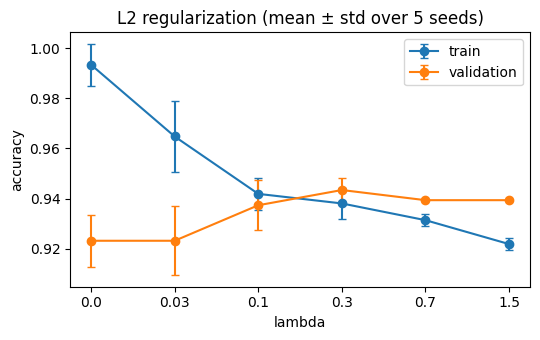

In [8]:
lambdas = [0.0, 0.03, 0.1, 0.3, 0.7, 1.5]
l2_results = {0.0: (base_rows, base_models)}
for lam in lambdas[1:]:
    l2_results[lam] = fit_eval(lambd=lam)

print("lambda | train acc | val acc | weight norm")
for lam, (rows, _) in l2_results.items():
    print(f"{lam:<6} | {pm(rows[:, 0])} | {pm(rows[:, 1])} | {rows[:, 3].mean():.1f}")

best_lambd = max(l2_results, key=lambda l: l2_results[l][0][:, 1].mean())
print("best lambda on validation:", best_lambd)

xs = np.arange(len(lambdas))
plt.figure(figsize=(5.5, 3.5))
for col, name in [(0, "train"), (1, "validation")]:
    plt.errorbar(xs, [l2_results[l][0][:, col].mean() for l in lambdas],
                 yerr=[l2_results[l][0][:, col].std() for l in lambdas], marker="o", capsize=3, label=name)
plt.xticks(xs, lambdas)
plt.xlabel("lambda")
plt.ylabel("accuracy")
plt.legend()
plt.title("L2 regularization (mean ± std over 5 seeds)")
plt.tight_layout()
plt.savefig(ASSETS / "l2_sweep.png", dpi=150)
plt.show()

## 4. Dropout: keep probability sweep (selected on validation)

keep_prob | train acc | val acc
1.0       | 99.3 ± 0.8 | 92.3 ± 1.0
0.9       | 97.4 ± 1.0 | 93.7 ± 0.8
0.8       | 96.1 ± 0.9 | 94.7 ± 0.4
0.7       | 95.1 ± 0.2 | 94.7 ± 0.4
0.5       | 94.3 ± 0.0 | 94.1 ± 0.4
best keep_prob on validation: 0.8


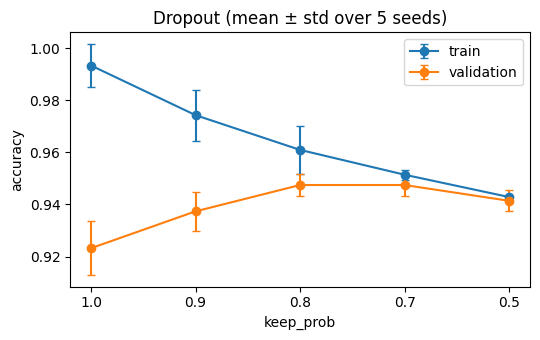

In [9]:
keep_probs = [1.0, 0.9, 0.8, 0.7, 0.5]
do_results = {1.0: (base_rows, base_models)}
for kp in keep_probs[1:]:
    do_results[kp] = fit_eval(keep_prob=kp)

print("keep_prob | train acc | val acc")
for kp, (rows, _) in do_results.items():
    print(f"{kp:<9} | {pm(rows[:, 0])} | {pm(rows[:, 1])}")

best_keep = max(do_results, key=lambda k: do_results[k][0][:, 1].mean())
print("best keep_prob on validation:", best_keep)

xs = np.arange(len(keep_probs))
plt.figure(figsize=(5.5, 3.5))
for col, name in [(0, "train"), (1, "validation")]:
    plt.errorbar(xs, [do_results[k][0][:, col].mean() for k in keep_probs],
                 yerr=[do_results[k][0][:, col].std() for k in keep_probs], marker="o", capsize=3, label=name)
plt.xticks(xs, keep_probs)
plt.xlabel("keep_prob")
plt.ylabel("accuracy")
plt.legend()
plt.title("Dropout (mean ± std over 5 seeds)")
plt.tight_layout()
plt.savefig(ASSETS / "dropout_sweep.png", dpi=150)
plt.show()

## 5. Final comparison on the test set

setting                            | train acc | test acc
no regularization                  | 99.3 ± 0.8 | 91.4 ± 1.0
L2 (lambda=0.3)                    | 93.8 ± 0.6 | 93.4 ± 1.4
dropout (keep_prob=0.8)            | 96.1 ± 0.9 | 92.8 ± 0.7
L2 + dropout (0.3, 0.8)            | 94.2 ± 0.2 | 92.2 ± 0.4
majority-class baseline: 44.0%


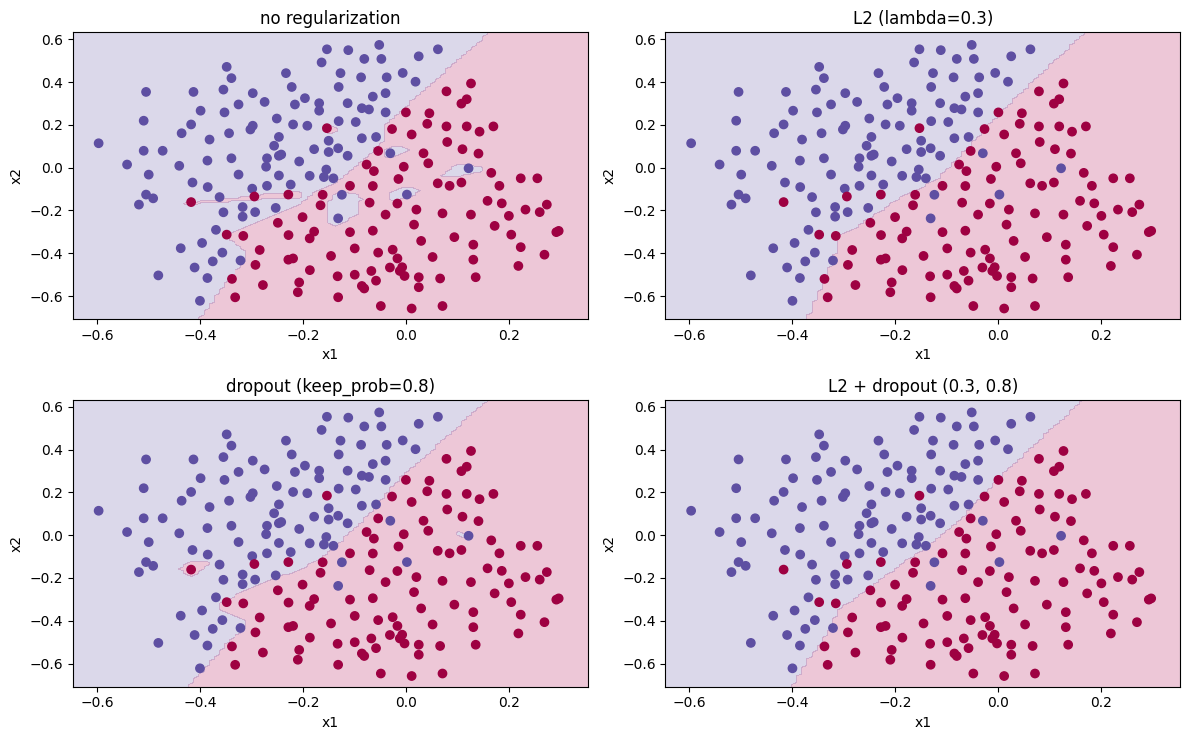

In [10]:
both_rows, both_models = fit_eval(lambd=best_lambd, keep_prob=best_keep)

settings = {
    "no regularization": (base_rows, base_models),
    f"L2 (lambda={best_lambd})": l2_results[best_lambd],
    f"dropout (keep_prob={best_keep})": do_results[best_keep],
    f"L2 + dropout ({best_lambd}, {best_keep})": (both_rows, both_models),
}
print(f"{'setting':<34} | train acc | test acc")
for name, (rows, _) in settings.items():
    print(f"{name:<34} | {pm(rows[:, 0])} | {pm(rows[:, 2])}")
print(f"majority-class baseline: {np.mean(Y_te == majority):.1%}")

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, (name, (rows, models)) in zip(axes.ravel(), settings.items()):
    plot_decision_boundary(models[0].predict, X_tr, Y_tr, ax, name)
plt.tight_layout()
plt.savefig(ASSETS / "decision_boundaries.png", dpi=150)
plt.show()

## 6. Results and notes

- **Baseline.**
  Train 99.3 ± 0.8 vs test 91.4 ± 1.0 (gap ≈ 8 pp, i.e. ≈ 8 of 100 test examples);
  val 92.3 ± 1.0 and test 91.4 ± 1.0 nearly coincide, so the gap is not an artefact of
  the split. Weight norm 29.3. The decision boundary is ragged, with small "islands"
  around individual points: the network fits the noise rather than the global structure
  of the data.

- **L2.**
  Best λ = 0.3 on validation (val 94.3 ± 0.5, test 93.4 ± 1.4). Weight norm falls
  monotonically with λ (29.3 / 8.4 / 4.5 at λ = 0 / 0.3 / 1.5). At λ = 0.3 the train–val
  gap is ≈ 0.5 pp with high train, so no underfitting. Larger λ (0.7, 1.5) give
  val 93.9 ± 0.0, overlapping λ = 0.3's [93.8, 94.8] — indistinguishable on val, so the
  tie goes to the higher train (93.8, 93.1, 92.2 for λ = 0.3, 0.7, 1.5). The boundary is
  visibly smoother and no longer wraps around individual noisy points.

- **Dropout.**
  Best keep_prob = 0.8 on validation (val 94.7 ± 0.4, test 92.8 ± 0.7). keep_prob 0.7
  gives the same val (94.7 ± 0.4), so the two are indistinguishable and 0.8 is picked by
  the `max` rule. Dropout lowers train (99.3 to 96.1) less than L2 (to 93.8), and its
  test is slightly below L2 (92.8 vs 93.4). The boundary is cleaner than the baseline but
  still has local pockets around individual points, so overfitting is reduced but not
  removed.

- **Seed-to-seed spread.**
  Criterion: do the `mean ± std` intervals overlap or not.
  - **Real:** baseline vs any regularization — 92.3 ± 1.0 vs 94.3 ± 0.5 and vs 94.7 ± 0.4
    (no overlap).
  - **Noise:** everything within regularized variants — λ = 0.1 / 0.3 / 0.7; dropout 0.8
    vs 0.7 (identical 94.7 ± 0.4); L2 vs dropout on test; L2 + dropout vs L2 on test.
  Caveat: 5 seeds, ~100 test examples — weak statistics.

- **L2 + dropout.**
  Test 92.2 ± 0.4 is the lowest, but it overlaps with L2-only (93.4 ± 1.4), so we cannot
  claim it is worse. Train and test differences from L2-only (94.2 vs 93.8 and 92.2 vs
  93.4) are both within seed spread. The observed direction — slightly higher train,
  slightly lower test — does not fit a simple "stacked regularizers underfit" story,
  since that would predict lower train. A more plausible account is that dropout and L2
  act on weights in opposite directions (dropout inflates weights, L2 shrinks them), so
  their combination is not a simple sum of capacities. With 5 seeds and ~100 test points,
  none of this is established; it is a direction worth checking with more seeds.

- **Why dropout is off at prediction time.**
  Dropout is a training regularizer; at inference we want full capacity and a
  deterministic answer (checked in `test_prediction_is_deterministic_and_ignores_dropout`).
  With inverted dropout, training divides by keep_prob, so keep_prob = 1.0 at test gives
  the unbiased expected activation — an implicit ensemble average in one pass. Leaving it
  on would give a random, biased prediction. 